## Câu 1. Đọc dữ liệu Groceries và khảo sát giao dịch

In [7]:
import csv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 6, Câu 1")

tep_du_lieu = Path("data/groceries.csv")
if not tep_du_lieu.exists():
    raise FileNotFoundError(f"Không tìm thấy file: {tep_du_lieu.resolve()}")

with tep_du_lieu.open("r", encoding="utf-8-sig", newline="") as tep:
    giao_dich = [
        list(dict.fromkeys(mat_hang.strip() for mat_hang in dong if mat_hang.strip()))
        for dong in csv.reader(tep)
    ]
    
giao_dich = [dong for dong in giao_dich if dong]

so_giao_dich = len(giao_dich)
danh_sach_mat_hang = sorted({mat_hang for dong in giao_dich for mat_hang in dong})
do_dai_giao_dich = [len(dong) for dong in giao_dich]

print("\nSố lượng giao dịch:", so_giao_dich)
print("Số loại mặt hàng:", len(danh_sach_mat_hang))
print("Số mặt hàng trung bình trong một giao dịch:", round(np.mean(do_dai_giao_dich), 2))
print("Giao dịch có nhiều mặt hàng nhất:", max(do_dai_giao_dich))
print("\nNăm giao dịch đầu tiên")
for vi_tri, dong in enumerate(giao_dich[:5], start=1):
    print(f"Giao dịch {vi_tri}: {', '.join(dong)}")

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 6, Câu 1

Số lượng giao dịch: 9835
Số loại mặt hàng: 169
Số mặt hàng trung bình trong một giao dịch: 4.41
Giao dịch có nhiều mặt hàng nhất: 32

Năm giao dịch đầu tiên
Giao dịch 1: citrus fruit, semi-finished bread, margarine, ready soups
Giao dịch 2: tropical fruit, yogurt, coffee
Giao dịch 3: whole milk
Giao dịch 4: pip fruit, yogurt, cream cheese, meat spreads
Giao dịch 5: other vegetables, whole milk, condensed milk, long life bakery product


## Câu 2. Mã hóa dữ liệu giao dịch về dạng One-hot Encoding

In [8]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 6, Câu 2")

from mlxtend.preprocessing import TransactionEncoder

bo_ma_hoa = TransactionEncoder()
ma_tran_one_hot = bo_ma_hoa.fit(giao_dich).transform(giao_dich)
gio_hang_one_hot = pd.DataFrame(ma_tran_one_hot, columns=bo_ma_hoa.columns_)

print("\nKích thước bảng One-hot")
print("Số giao dịch:", gio_hang_one_hot.shape[0])
print("Số mặt hàng:", gio_hang_one_hot.shape[1])
print("\nNăm giao dịch đầu tiên và 12 mặt hàng đầu tiên")
print(gio_hang_one_hot.iloc[:5, :12].to_string(index=False))
print("\nSố mặt hàng có trong mỗi giao dịch đầu tiên")
print(gio_hang_one_hot.sum(axis=1).head(5).to_string(index=False))

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 6, Câu 2

Kích thước bảng One-hot
Số giao dịch: 9835
Số mặt hàng: 169

Năm giao dịch đầu tiên và 12 mặt hàng đầu tiên
 Instant food products  UHT-milk  abrasive cleaner  artif. sweetener  baby cosmetics  baby food  bags  baking powder  bathroom cleaner  beef  berries  beverages
                 False     False             False             False           False      False False          False             False False    False      False
                 False     False             False             False           False      False False          False             False False    False      False
                 False     False             False             False           False      False False          False             False False    False      False
                 False     False             False             False           False      False False          False             False False    False      False
                 F

## Câu 3. Tìm tập phổ biến bằng Apriori và đo thời gian xử lý

In [9]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 6, Câu 3")

import time
from mlxtend.frequent_patterns import apriori

nguong_phan_tram = [round(i / 100, 2) for i in range(1, 11)]

gioi_han_do_dai = 2

ket_qua_apriori = []
cac_tap_apriori = {}

for nguong in nguong_phan_tram:
    nguong_thuc = nguong / 100
    bat_dau = time.perf_counter()

    tap_pho_bien = apriori(
        gio_hang_one_hot,
        min_support=nguong_thuc,
        use_colnames=True,
        low_memory=True,
        max_len=gioi_han_do_dai
    )

    thoi_gian = time.perf_counter() - bat_dau
    cac_tap_apriori[nguong] = tap_pho_bien
    ket_qua_apriori.append({
        "Ngưỡng min_sup (%)": nguong,
        "Số tập phổ biến": len(tap_pho_bien),
        "Thời gian (giây)": round(thoi_gian, 4)
    })

bang_apriori = pd.DataFrame(ket_qua_apriori)
print("\nKết quả Apriori theo từng ngưỡng")
print(bang_apriori.to_string(index=False))
print("\nPhạm vi thống kê: tập phổ biến có tối đa 2 mặt hàng")

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 6, Câu 3

Kết quả Apriori theo từng ngưỡng
 Ngưỡng min_sup (%)  Số tập phổ biến  Thời gian (giây)
               0.01             9805            0.0327
               0.02             7689            0.0278
               0.03             6412            0.0259
               0.04             5591            0.0245
               0.05             4946            0.0239
               0.06             4446            0.0237
               0.07             4048            0.0248
               0.08             3699            0.0215
               0.09             3398            0.0231
               0.10             3138            0.0200

Phạm vi thống kê: tập phổ biến có tối đa 2 mặt hàng


## Câu 4. Tìm tập phổ biến bằng FP-Growth và đo thời gian xử lý

In [10]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 6, Câu 4")

from mlxtend.frequent_patterns import fpgrowth

ket_qua_fp = []
cac_tap_fp = {}

for nguong in nguong_phan_tram:
    nguong_thuc = nguong / 100
    bat_dau = time.perf_counter()

    tap_pho_bien = fpgrowth(
        gio_hang_one_hot,
        min_support=nguong_thuc,
        use_colnames=True,
        max_len=gioi_han_do_dai
    )

    thoi_gian = time.perf_counter() - bat_dau
    cac_tap_fp[nguong] = tap_pho_bien
    ket_qua_fp.append({
        "Ngưỡng min_sup (%)": nguong,
        "Số tập phổ biến": len(tap_pho_bien),
        "Thời gian (giây)": round(thoi_gian, 4)
    })

bang_fp = pd.DataFrame(ket_qua_fp)
print("\nKết quả FP-Growth theo từng ngưỡng")
print(bang_fp.to_string(index=False))
print("\nPhạm vi thống kê: tập phổ biến có tối đa 2 mặt hàng")

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 6, Câu 4

Kết quả FP-Growth theo từng ngưỡng
 Ngưỡng min_sup (%)  Số tập phổ biến  Thời gian (giây)
               0.01             9805            0.6159
               0.02             7689            0.5070
               0.03             6412            0.4913
               0.04             5591            0.3815
               0.05             4946            0.3701
               0.06             4446            0.2737
               0.07             4048            0.3411
               0.08             3699            0.3143
               0.09             3398            0.3350
               0.10             3138            0.2239

Phạm vi thống kê: tập phổ biến có tối đa 2 mặt hàng


## Câu 5. Vẽ biểu đồ so sánh thời gian Apriori và FP-Growth

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 6, Câu 5

Bảng so sánh kết quả
 Ngưỡng min_sup (%)  Số tập phổ biến Apriori  Thời gian (giây) Apriori  Số tập phổ biến FP-Growth  Thời gian (giây) FP-Growth
               0.01                     9805                    0.0327                       9805                      0.6159
               0.02                     7689                    0.0278                       7689                      0.5070
               0.03                     6412                    0.0259                       6412                      0.4913
               0.04                     5591                    0.0245                       5591                      0.3815
               0.05                     4946                    0.0239                       4946                      0.3701
               0.06                     4446                    0.0237                       4446                      0.2737
               0.07         

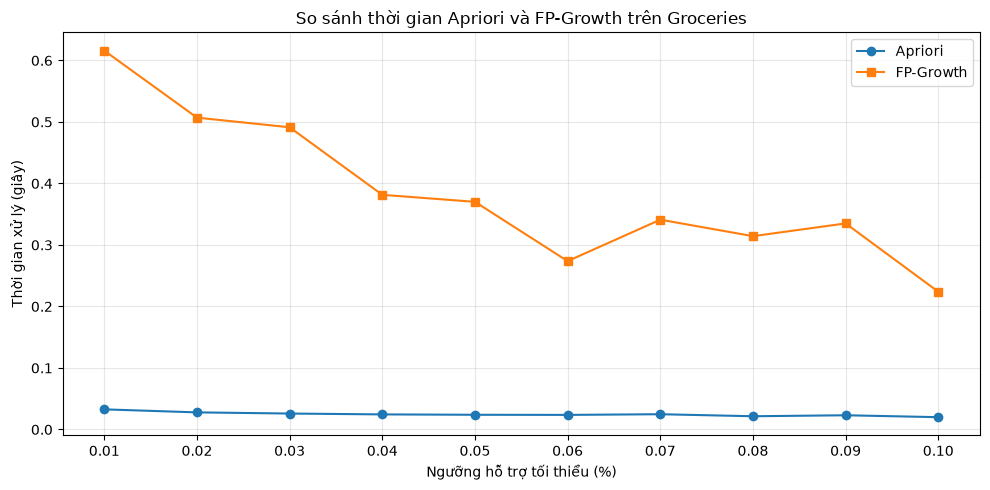

In [11]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 6, Câu 5")

so_sanh = bang_apriori.merge(
    bang_fp,
    on="Ngưỡng min_sup (%)",
    suffixes=(" Apriori", " FP-Growth")
)

print("\nBảng so sánh kết quả")
print(so_sanh.to_string(index=False))

plt.figure(figsize=(10, 5))
plt.plot(
    so_sanh["Ngưỡng min_sup (%)"],
    so_sanh["Thời gian (giây) Apriori"],
    marker="o",
    label="Apriori"
)
plt.plot(
    so_sanh["Ngưỡng min_sup (%)"],
    so_sanh["Thời gian (giây) FP-Growth"],
    marker="s",
    label="FP-Growth"
)
plt.xlabel("Ngưỡng hỗ trợ tối thiểu (%)")
plt.ylabel("Thời gian xử lý (giây)")
plt.title("So sánh thời gian Apriori và FP-Growth trên Groceries")
plt.xticks(nguong_phan_tram)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Câu 6. Đối chiếu tập phổ biến, rút ra nhận xét và giải thích

In [12]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 6, Câu 6")

ket_qua_kiem_tra = []
for nguong in nguong_phan_tram:
    tap_a = {
        frozenset(hang.itemsets): round(float(hang.support), 12)
        for hang in cac_tap_apriori[nguong].itertuples(index=False)
    }
    tap_f = {
        frozenset(hang.itemsets): round(float(hang.support), 12)
        for hang in cac_tap_fp[nguong].itertuples(index=False)
    }
    ket_qua_kiem_tra.append({
        "Ngưỡng min_sup (%)": nguong,
        "Số tập Apriori": len(tap_a),
        "Số tập FP-Growth": len(tap_f),
        "Trùng khớp": tap_a == tap_f
    })

bang_kiem_tra = pd.DataFrame(ket_qua_kiem_tra)
print("\nĐối chiếu kết quả hai thuật toán")
print(bang_kiem_tra.to_string(index=False))

print("\nTổng thời gian thử nghiệm")
print("Apriori:", round(bang_apriori["Thời gian (giây)"].sum(), 4), "giây")
print("FP-Growth:", round(bang_fp["Thời gian (giây)"].sum(), 4), "giây")

nhanh_hon = np.where(
    so_sanh["Thời gian (giây) Apriori"] < so_sanh["Thời gian (giây) FP-Growth"],
    "Apriori",
    np.where(
        so_sanh["Thời gian (giây) Apriori"] > so_sanh["Thời gian (giây) FP-Growth"],
        "FP-Growth",
        "Bằng nhau"
    )
)
print("\nThuật toán nhanh hơn theo từng ngưỡng")
print(pd.DataFrame({
    "Ngưỡng min_sup (%)": nguong_phan_tram,
    "Thuật toán nhanh hơn": nhanh_hon
}).to_string(index=False))

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 6, Câu 6

Đối chiếu kết quả hai thuật toán
 Ngưỡng min_sup (%)  Số tập Apriori  Số tập FP-Growth  Trùng khớp
               0.01            9805              9805        True
               0.02            7689              7689        True
               0.03            6412              6412        True
               0.04            5591              5591        True
               0.05            4946              4946        True
               0.06            4446              4446        True
               0.07            4048              4048        True
               0.08            3699              3699        True
               0.09            3398              3398        True
               0.10            3138              3138        True

Tổng thời gian thử nghiệm
Apriori: 0.2479 giây
FP-Growth: 3.8538 giây

Thuật toán nhanh hơn theo từng ngưỡng
 Ngưỡng min_sup (%) Thuật toán nhanh hơn
               0.01  